In [ ]:
!pip install matplotlib-label-lines

import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from labellines import labelLines

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 826.2/826.2 kB 9.9 MB/s  0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#filename = "BH_solve_ODE_logs_2026-10-04_10-38-11.txt"
filename = "IBH_solve_ODE_logs_2026-10-04_19-26-27.txt"
#filename = "SBH_solve_ODE_logs_2026-10-04_19-42-01.txt"
#filename = "Sun_solve_ODE_logs_2026-10-04_14-23-26.txt"
#filename = "star_solve_ODE_logs_2026-10-04_14-27-48.txt"

file_path = '/content/drive/My Drive/Colab Notebooks/Project/ODE with Matrix Elements frfr/ode_data/'+filename
try:
    with open(file_path, 'r') as f:
        text = f.read()
        lines = text.splitlines()
except Exception as e:
    print(f"An error occurred: {e}")

In [ ]:
xi_values = []
f_values = []
T_values = []
N_1s_values = []
N_2s_values = []
N_2p_values = []

for i in range(len(lines)-2):
  if ("Found a match" in lines[i]):
    pieces = lines[i+1].split(" ")
    xi = float(pieces[0][3:-1])
    f = float(pieces[1][2:-4])
    T = float(pieces[2][2:-5])

    pieces = lines[i+2].split(" ")
    N_1s = float(pieces[0][4:-1])
    N_2s = float(pieces[1][4:-1])
    N_2p = float(pieces[2][4:])

    xi_values.append(xi)
    f_values.append(f)
    T_values.append(T)

    N_1s_values.append(N_1s)
    N_2s_values.append(N_2s)
    N_2p_values.append(N_2p)

xi_values = np.array(xi_values)
f_values = np.array(f_values)
T_values = np.array(T_values)
N_1s_values = np.array(N_1s_values)
N_2s_values = np.array(N_2s_values)
N_2p_values = np.array(N_2p_values)

In [ ]:
rho_0=0.38 #NFW density in GeV/cm^3
r_0=18600.0 #NFW scale in pc

def NFW(r):
    '''NFW density profile in GeV/cm^3. r is measured in pc'''
    return rho_0/(r/r_0 * (1+r/r_0)**2)

In [ ]:
if (filename.startswith("Sun")):
  M_tilde = 1
  v_tilde = 1
  rho_tilde = 1
elif (filename.startswith("BH")):
  M_tilde = 10
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("IBH")):
  M_tilde = 1e3
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("SBH")):
  M_tilde = 1e5
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
elif (filename.startswith("star")):
  M_tilde = 10
  v_tilde = 1
  rho_tilde = NFW(1e3)/0.4
else:
  print("Unkown astro_regime")

alpha_values = xi_values * 8e-4
alpha_0 = 7.5*1e-5
m_tilde_values = alpha_values/alpha_0/M_tilde
f_tilde_values = f_values/1e8

actual_N_k_values = 6.85591e61 * rho_tilde * m_tilde_values**(-6) * M_tilde**(-2) * v_tilde**(-1)
#max_N_1s_values = 3e67 * f_tilde_values**2 * m_tilde_values**(-3) * M_tilde**(-1)
max_N_1s_values = 6.7e67 * f_tilde_values**2 * m_tilde_values**(-3) * M_tilde**(-1)
rho_crit_to_BG_1s_values = 2.9e4 * f_tilde_values**2 * m_tilde_values**4 * M_tilde**2 * rho_tilde**(-1)

# N_1s_mass_values = N_1s_values*actual_N_k_values*1.8e-50*m_tilde_values
# N_2s_mass_values = N_2s_values*actual_N_k_values*1.8e-50*m_tilde_values
# N_2p_mass_values = N_2p_values*actual_N_k_values*1.8e-50*m_tilde_values

# ratio of cloud mass to BH mass
N_1s_mass_values = N_1s_values*actual_N_k_values*9e-81*m_tilde_values / M_tilde
N_2s_mass_values = N_2s_values*actual_N_k_values*9e-81*m_tilde_values / M_tilde
N_2p_mass_values = 3*N_2p_values*actual_N_k_values*9e-81*m_tilde_values / M_tilde


# old silly density calculation
# N_1s_density_values = N_1s_values*actual_N_k_values/max_N_1s_values*rho_crit_to_BG_1s_values
# N_2s_density_values = N_2s_values*actual_N_k_values/max_N_1s_values*rho_crit_to_BG_1s_values/8
# N_2p_density_values = N_2p_values*actual_N_k_values/max_N_1s_values*rho_crit_to_BG_1s_values/(24*np.exp(2))

# # less old reasonable density calculation (relative to BG)
# N_1s_density_values = 4.14277e-52*N_1s_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)
# N_2s_density_values = 5.17845e-53*N_2s_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)
# N_2p_density_values = 7.00829e-54*N_2p_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)

# new reasonabler density calculation (relative to BG at 1 r_b)
N_1s_density_values = 5.607e-53*N_1s_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)
N_2s_density_values = 4.763e-54*N_2s_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)
N_2p_density_values = 4.763e-54*N_2p_values*actual_N_k_values*alpha_values**3*m_tilde_values**4 / (0.4 * rho_tilde)

In [ ]:
from matplotlib.colors import LogNorm

def log_edges(centers):
    '''Cell edges for log-spaced centers: geometric midpoints, extended by half a step at both ends'''
    log_c = np.log10(centers)
    mids = 0.5 * (log_c[1:] + log_c[:-1])
    edges = np.concatenate(([log_c[0] - (mids[0] - log_c[0])], mids, [log_c[-1] + (log_c[-1] - mids[-1])]))
    return 10**edges

def plot_on_grid(ax, xi_flat, f_flat, values_flat, vmin, vmax):
    '''Log-log colour plot of flat values over a flattened (xi, f) grid; returns the mesh for the colorbar'''
    xi_flat = np.asarray(xi_flat, dtype=float)
    f_flat = np.asarray(f_flat, dtype=float)
    values_flat = np.asarray(values_flat, dtype=float)

    xis, i_xi = np.unique(xi_flat, return_inverse=True)
    fs, i_f = np.unique(f_flat, return_inverse=True)
    grid = np.full((len(fs), len(xis)), np.nan)   # indexed [f, xi], as pcolormesh expects [y, x]
    grid[i_f, i_xi] = values_flat

    positive = values_flat[values_flat > 0]
    return ax.pcolormesh(log_edges(xis), log_edges(fs), grid,
                         #norm=LogNorm(vmin=positive.min(), vmax=positive.max()),
                         norm=LogNorm(vmin, vmax),
                         cmap='Blues', shading='flat',
                         edgecolors='face', linewidth=0.2, antialiased=True)

rho_0=0.38 #NFW density in GeV/cm^3
r_0=18600.0 #NFW scale in pc

def NFW(r):
    '''NFW density profile in GeV/cm^3. r is measured in pc'''
    return rho_0/(r/r_0 * (1+r/r_0)**2)

In [ ]:
label1s = r"$\Gamma_{\infty \rightarrow 1s}=\Gamma_{1s\rightarrow \text{BH}}$"
label2p = r"$\Gamma_{\infty \rightarrow 2p}=\Gamma_{2p\rightarrow \text{BH}}$"
labellifetime = r"$\Gamma^{-1}_{\infty\rightarrow 2p}=10^{10}$ years"
labelcosmo = r"cosmo. bound"

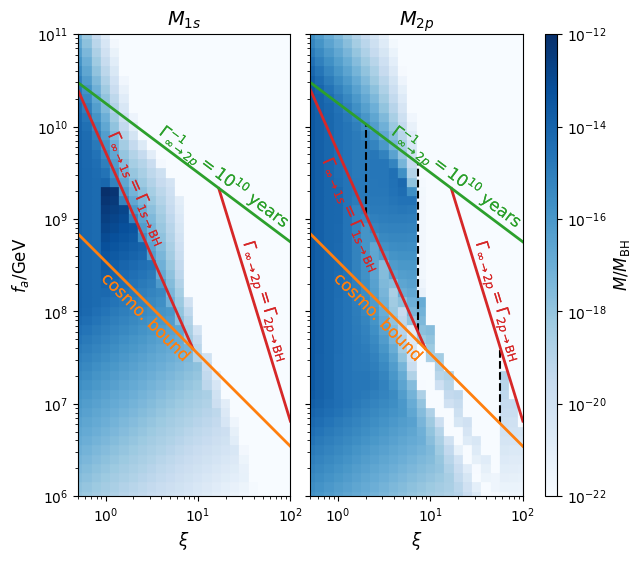

N1s min=1.536e-85, max=9.493e-13
N2s min=1.920e-85, max=5.998e-15
N2p min=7.200e-84, max=2.696e-14, at xi=0.5,f_a=800000000.0, 2.6963894743003315e-14


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(6, 6), sharey=True)
fig.subplots_adjust(wspace=0)


y_min = 1e4
y_max = 1e9
if (filename.startswith("star")):
  lower_bound = 1e-22
  upper_bound = 1e-14
elif (filename.startswith("BH")):
  lower_bound = 1e-26
  upper_bound = 1e-16
elif (filename.startswith("IBH")):
  lower_bound = 1e-22
  upper_bound = 1e-12
  y_min = 1e6
  y_max = 1e11
elif (filename.startswith("SBH")):
  lower_bound = 1e-18
  upper_bound = 1e-8
  y_min = 1e8
  y_max = 1e13
elif (filename.startswith("Sun")):
  lower_bound = 1e-25
  upper_bound = 1e-17
else:
  print("Unknown astro_regime")

axes[0].set_ylabel(r'$f_a/\text{GeV}$',size=12)
for ax in axes:
  ax.set_xlim(0.5, 100)
  ax.set_ylim(y_min, y_max)
  ax.set_xscale('log')
  ax.set_yscale('log')
  ax.set_aspect(1)
  ax.set_xlabel(r'$\xi$',size=12)


ax = axes[0]
mesh = plot_on_grid(ax, xi_values, f_values, N_1s_mass_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{1s}$, kg')
ax.set_title(r"$M_{1s}$",size=14)

ax = axes[1]
mesh = plot_on_grid(ax, xi_values, f_values, N_2p_mass_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{2s}$, kg')
ax.set_title(r"$M_{2p}$",size=14)

cax = fig.add_axes((0.92, 0.11, 0.02, 0.77))

if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
   colorbar=fig.colorbar(mesh, cax=cax, label='$M/M_\\text{BH}$')
   colorbar.set_label("$M/M_\\text{BH}$", size=12)
elif filename.startswith("Sun"):
  fig.colorbar(mesh, cax=cax, label='$M/M_\\odot$')

else:
  colorbar=fig.colorbar(mesh, cax=cax, label='$M/M_\\text{star}$')
  colorbar.set_label('$M/M_\\text{star}$', size=12)

if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
  XIS=np.logspace(np.log10(0.5),2,500)

  halo_1s = 0.1424 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-9/4) #tau_halo(1s) = $tau_{1s->BH} line
  halo_2p = 0.4425 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-13/4) # tau_halo(2p) = $tau_{2p->BH} line
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)
  halo_lifetime = (1e10)**0.25 * 378.5 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(2p) = 10^10 years
  halo_1s_masked = np.where( (halo_1s <= halo_lifetime) & (halo_1s >= cosmo_bound), halo_1s, np.nan)
  halo_2p_masked = np.where( (halo_2p <= halo_lifetime) & (halo_2p >= cosmo_bound), halo_2p, np.nan)
  indx_strong = (np.abs(XIS - 57)).argmin()
  indx_weak = (np.abs(XIS - 7.3)).argmin()
  indx2 = (np.abs(XIS - 2)).argmin()

  for i in range(2):
    ax=axes[i]
    vertical_lines=[]
    if i==1:
      ax.plot([XIS[indx2],XIS[indx2]],[halo_1s[indx2], halo_lifetime[indx2]],'--',color='black',linewidth=1.5, label=r'$\xi = 2$')
      ax.plot([XIS[indx_weak],XIS[indx_weak]],[halo_1s[indx_weak], halo_lifetime[indx_weak]],'--',color='black',linewidth=1.5, label=r'$\tau_{\infty \rightarrow 2p}=\tau_{2p\rightarrow 2s}$')
      ax.plot([XIS[indx_strong],XIS[indx_strong]],[cosmo_bound[indx_strong], halo_2p[indx_strong]],'--',color='black',linewidth=1.5, label=r'$\alpha \xi = 1$')
      vertical_lines = [line for line in ax.get_lines()]
      #labelLines(vertical_lines, align=True, xoffsets=[0.5,1.5,-12],yoffsets=[-5e7,-5e7,-7e4], fontsize=10,outline_width=0)

    ax.plot(XIS,halo_1s_masked, color='C3',linewidth=2, label=label1s)
    ax.plot(XIS,halo_2p_masked, color='C3',linewidth=2, label=label2p)
    ax.plot(XIS,halo_lifetime, color='C2',linewidth=2, label=labellifetime)
    ax.plot(XIS,cosmo_bound,color='C1',linewidth=2,label=labelcosmo)

    labeled_lines = [line for line in ax.get_lines()]
    for line in vertical_lines: labeled_lines.remove(line)
    if i==0:
      labelLines(labeled_lines, align=True, xvals=np.array([1.5,40,12,4]),xoffsets=[0.7,13,7,-1.3], fontsize=12,outline_width=0)
    else:
      labelLines(labeled_lines, align=True, xvals=np.array([2,40,12,4]),xoffsets=[-0.6,13,7,-1.3], fontsize=12,outline_width=0)

elif (filename.startswith("Sun"))or(filename.startswith("star")):
  XIS=np.logspace(np.log10(0.5),2,500)
  halo_lifetime = (1e10)**0.25 * 381 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(1s) = 10^10 years
  #cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)

  for i in range(2):
    ax=axes[i]
    ax.plot(XIS,halo_lifetime, color='limegreen',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")
    #ax.plot(XIS,cosmo_bound,'c',linewidth=2,label='cosmological bound')
    labeled_lines = [line for line in ax.get_lines()]
    labelLines(labeled_lines, align=True, xvals=np.array([5]), fontsize=12,outline_width=0)

if (filename.startswith("star")):
  plt.savefig("star_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for a star with $M=10\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("BH")):
  plt.savefig("BH_mass_parameter_space.pdf", bbox_inches="tight")
  #plt.suptitle(r"Halo mass for a BH with $M_{\text{BH}}=10\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("IBH")):
  plt.savefig("IBH_mass_parameter_space.pdf", bbox_inches="tight")
  #plt.suptitle(r"Halo mass for an IBH with $M_{\text{BH}}=10^3\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("SBH")):
  plt.savefig("SBH_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for a SBH with $M_{\text{BH}}=10^5 M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("Sun")):
  plt.savefig("Sun_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for the Sun $M=M_{\odot}$, $r=8\ \text{kpc}$")
else:
  print("Unknown astro_regime")
plt.show()

argmax=np.argmax(N_2p_mass_values*(f_values>(277 * M_tilde * (xi_values*0.0008)**(-1)))) #2p maximal mass is evaluated for parameters not violating the cosmo. bound
print(f"N1s min={np.min(N_1s_mass_values):.3e}, max={np.max(N_1s_mass_values):.3e}")
print(f"N2s min={np.min(N_2s_mass_values):.3e}, max={np.max(N_2s_mass_values):.3e}")
print(f"N2p min={np.min(N_2p_mass_values):.3e}, max={np.max(N_2p_mass_values):.3e}, at xi={xi_values[argmax]},f_a={f_values[argmax]}, {N_2p_mass_values[argmax]}")

N1s min=1.567e-69, max=1.478e+03
N2s min=6.348e-70, max=5.108e+02
N2p min=3.027e-62, max=1.451e+05


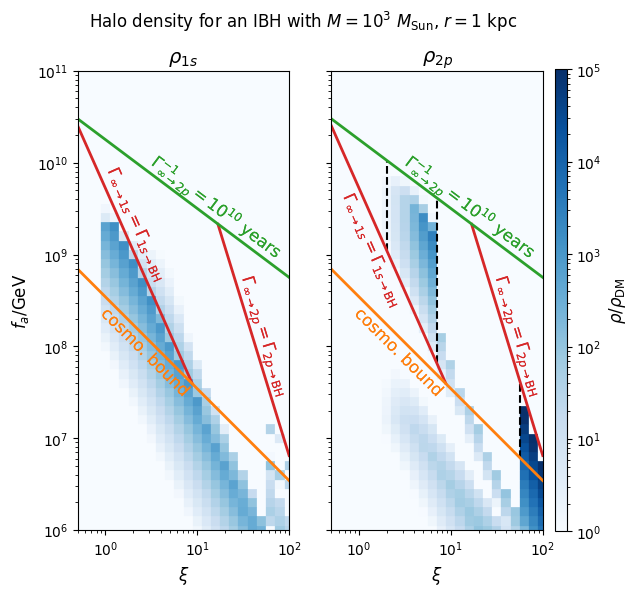

In [ ]:
print(f"N1s min={np.min(N_1s_density_values):.3e}, max={np.max(N_1s_density_values):.3e}")
print(f"N2s min={np.min(N_2s_density_values):.3e}, max={np.max(N_2s_density_values):.3e}")
print(f"N2p min={np.min(N_2p_density_values):.3e}, max={np.max(N_2p_density_values):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(6, 6), sharey=True)
#fig.subplots_adjust(wspace=0)

y_min = 1e4
y_max = 1e9
if (filename.startswith("star")):
  lower_bound = 1e0
  upper_bound = 1e10
elif (filename.startswith("BH")):
  lower_bound = 1e0
  upper_bound = 1e5
elif (filename.startswith("IBH")):
  lower_bound = 1e0
  upper_bound = 1e5
  y_min = 1e6
  y_max = 1e11
elif (filename.startswith("SBH")):
  lower_bound = 1e0
  upper_bound = 1e5
  y_min = 1e8
  y_max = 1e13
elif (filename.startswith("Sun")):
  lower_bound = 1e-2
  upper_bound = 1e0
else:
  print("Unknown astro_regime")

axes[0].set_ylabel(r'$f_a/\text{GeV}$',size=12)
for ax in axes:

  ax.set_xscale('log')
  ax.set_yscale('log')
  ax.set_ylim(y_min, y_max)
  ax.set_xlabel(r'$\xi$',size=12)
  if filename.startswith("Sun"):
    ax.set_xlim(0.5, 1.82)
    ax.set_aspect(0.2)
    ax.xaxis.set_major_locator(ticker.FixedLocator([0.5,1,1.5]))
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    #ax.set_xticks([0.5,1,1.5],labels=["0.5","1","1.5"])

    secax = ax.secondary_xaxis('top', functions=(lambda x: 0.0154*(x**(-2)), lambda x: 0.124*(x**(-0.5))))
    secax.set_xlabel(r"$r_b/\text{AU}$")

    #secax.xaxis.set_major_locator(ticker.FixedLocator([0.015, 0.01]))
    #ax.xaxis.set_minor_locator(ticker.NullLocator())
    secax.set_xticks([0.01,0.05,0.005,0.0001],labels=["0.01","0.05","0.005","0.0001"])
  else:
    ax.set_xlim(0.5, 100)
    ax.set_aspect(1)


ax = axes[0]
mesh = plot_on_grid(ax, xi_values, f_values, N_1s_density_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{1s}$, kg')
ax.set_title(r"$\rho_{1s}$",size=14)

ax = axes[1]
mesh = plot_on_grid(ax, xi_values, f_values, N_2p_density_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{2s}$, kg')
ax.set_title(r"$\rho_{2p}$",size=14)

cax = fig.add_axes((0.92, 0.11, 0.02, 0.77))
colorbar=fig.colorbar(mesh, cax=cax, label=r'$\rho/\rho_{\text{DM}}$')
colorbar.set_label(r'$\rho/\rho_{\text{DM}}$', size=12)



if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
  XIS=np.logspace(np.log10(0.5),2,500)

  halo_1s = 0.1424 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-9/4) #tau_halo(1s) = $tau_{1s->BH} line
  halo_2p = 0.4425 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-13/4) # tau_halo(2p) = $tau_{2p->BH} line
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)
  halo_lifetime = (1e10)**0.25 * 378.5 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(2p) = 10^10 years
  halo_1s_masked = np.where( (halo_1s <= halo_lifetime) & (halo_1s >= cosmo_bound), halo_1s, np.nan)
  halo_2p_masked = np.where( (halo_2p <= halo_lifetime) & (halo_2p >= cosmo_bound), halo_2p, np.nan)
  # halo_1s_masked = np.where( (halo_1s <= halo_lifetime), halo_1s, np.nan)
  # halo_2p_masked = np.where( (halo_2p <= halo_lifetime), halo_2p, np.nan)
  indx_strong = (np.abs(XIS - 57)).argmin()
  indx_weak = (np.abs(XIS - 7)).argmin()
  indx2 = (np.abs(XIS - 2)).argmin()


  for i in range(2):
    ax=axes[i]
    vertical_lines = []
    if i==1:
      ax.plot([XIS[indx2],XIS[indx2]],[halo_1s[indx2], halo_lifetime[indx2]],'--',color='black',linewidth=1.5, label=r'$\xi = 2$')
      ax.plot([XIS[indx_weak],XIS[indx_weak]],[halo_1s[indx_weak], halo_lifetime[indx_weak]],'--',color='black',linewidth=1.5, label=r'$\tau_{\infty \rightarrow 2p}=\tau_{2p\rightarrow 2s}$')
      ax.plot([XIS[indx_strong],XIS[indx_strong]],[cosmo_bound[indx_strong], halo_2p[indx_strong]],'--',color='black',linewidth=1.5, label=r'$\alpha \xi = 1$')
      vertical_lines = [line for line in ax.get_lines()]
      #labelLines(vertical_lines, align=True, xoffsets=[0.5,1.5,-12],yoffsets=[-5e7,-5e7,-7e4], fontsize=10,outline_width=0)

    ax.plot(XIS,halo_1s_masked, color='C3',linewidth=2, label=label1s)
    ax.plot(XIS,halo_2p_masked, color='C3',linewidth=2, label=label2p)
    ax.plot(XIS,halo_lifetime, color='C2',linewidth=2, label=labellifetime)
    ax.plot(XIS,cosmo_bound,color='C1',linewidth=2,label=labelcosmo)

    labeled_lines = [line for line in ax.get_lines()]
    for line in vertical_lines: labeled_lines.remove(line)
    if i==0:
      labelLines(labeled_lines, align=True, xvals=np.array([1.5,40,10,4]),xoffsets=[0.7,13,6,-1.3], fontsize=12,outline_width=0)
    else:
      labelLines(labeled_lines, align=True, xvals=np.array([2,40,10,4]),xoffsets=[-0.6,13,6,-1.3], fontsize=12,outline_width=0)

elif (filename.startswith("Sun"))or(filename.startswith("star")):
  XIS=np.logspace(np.log10(0.5),2,500)
  halo_lifetime = (1e10)**0.25 * 381 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(1s) = 10^10 years
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)

  for i in range(2):
    ax=axes[i]
    ax.plot(XIS,halo_lifetime, 'g',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")
    ax.plot(XIS,cosmo_bound,'c',linewidth=2,label='cosmological bound')
    labeled_lines = [line for line in ax.get_lines()]

    labelLines(labeled_lines, align=True, xvals=np.array([1,1]),xoffsets=[-0.5,10,3,-2], fontsize=12,outline_width=0)


if (filename.startswith("star")):
  plt.savefig("star_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for a star with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("BH")):
  plt.savefig("BH_density_parameter_space.pdf", bbox_inches="tight")
  #plt.suptitle(r"Halo density for a BH with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("IBH")):
  plt.savefig("IBH_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for an IBH with $M=10^3\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("SBH")):
  plt.savefig("SBH_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for an SBH with $M=10^5\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("Sun")):
  plt.savefig("Sun_density_parameter_space.pdf", bbox_inches="tight")
  #plt.suptitle(r"Halo density for the Sun $M=M_{\text{Sun}}$, $r=8\ \text{kpc}$")
else:
  print("Unknown astro_regime")



plt.show()

# Checking the fixed point

In [ ]:
def fixed_point(xi_values,f_values,dilute=True):
  gamma_inf2p = 4.5
  gamma_1s_2p1s = 4.3e-5
  gamma_k_2p1s = np.exp(-0.475*xi_values**2+0.94*xi_values+3.4)*(1-0.06*xi_values-0.15)*1e-5
  Gamma = 0.163024 * m_tilde_values**9 * M_tilde**5 * v_tilde**2 * f_tilde_values**4 /(rho_tilde**2)
  if dilute:
    N_2p_approx = actual_N_k_values*(np.sqrt(6*Gamma*(gamma_inf2p**2)*gamma_1s_2p1s + xi_values**4 * Gamma**2 * gamma_k_2p1s**2)
    - xi_values**2*Gamma*(gamma_k_2p1s))/(3*gamma_inf2p*gamma_1s_2p1s)*9e-81*m_tilde_values / M_tilde
  #else:
  # N_2p_approx =

  return N_2p_approx

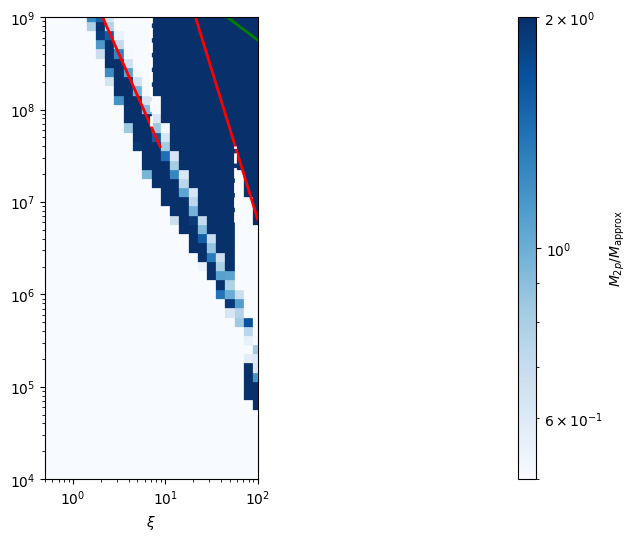

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(9, 6), sharey=True)
mesh = plot_on_grid(ax, xi_values, f_values,fixed_point(xi_values,f_values)/N_2p_mass_values, 0.5, 2)
cax = fig.add_axes((0.92, 0.11, 0.02, 0.77))
fig.colorbar(mesh, cax=cax, label='$M_{2p}/M_\\text{approx}$')
ax.set_xlim(0.5, 100)
ax.set_ylim(1e4, 1e9)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_aspect(1)
ax.set_xlabel(r'$\xi$')
ax.plot(XIS,halo_1s_masked, 'r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 1s}=\\tau_{\\text{1s}\\rightarrow \\text{BH}}$")
ax.plot(XIS,halo_2p_masked, 'r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 2p}=\\tau_{2p \\rightarrow \\text{BH}}$")
ax.plot(XIS,halo_lifetime, 'g',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")
ax.plot([XIS[indx_weak],XIS[indx_weak]],[halo_1s[indx_weak], halo_lifetime[indx_weak]],'w--',linewidth=2)
ax.plot([XIS[indx_strong],XIS[indx_strong]],[cosmo_bound[indx_strong], halo_2p[indx_strong]],'w--',linewidth=2)

# Plotting 2s

/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child1), but could not find a label for it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child2), but could not find a label for it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child3), but could not find a label for it.
  warnings.warn(


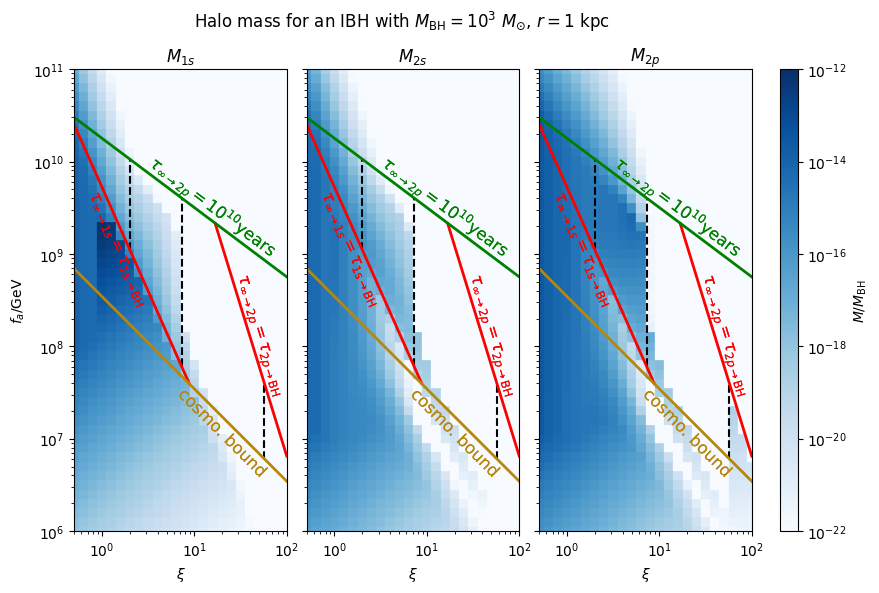

N1s min=1.536e-85, max=9.493e-13
N2s min=1.920e-85, max=5.998e-15
N2p min=7.200e-84, max=2.696e-14, at xi=0.5,f_a=800000000.0, 2.6963894743003315e-14


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(9, 6), sharey=True)
fig.subplots_adjust(wspace=0)


y_min = 1e4
y_max = 1e9
if (filename.startswith("star")):
  lower_bound = 1e-22
  upper_bound = 1e-14
elif (filename.startswith("BH")):
  lower_bound = 1e-26
  upper_bound = 1e-16
elif (filename.startswith("IBH")):
  lower_bound = 1e-22
  upper_bound = 1e-12
  y_min = 1e6
  y_max = 1e11
elif (filename.startswith("SBH")):
  lower_bound = 1e-18
  upper_bound = 1e-8
  y_min = 1e8
  y_max = 1e13
elif (filename.startswith("Sun")):
  lower_bound = 1e-25
  upper_bound = 1e-17
else:
  print("Unknown astro_regime")

axes[0].set_ylabel(r'$f_a/\text{GeV}$')
for ax in axes:
  ax.set_xlim(0.5, 100)
  ax.set_ylim(y_min, y_max)
  ax.set_xscale('log')
  ax.set_yscale('log')
  ax.set_aspect(1)
  ax.set_xlabel(r'$\xi$')


ax = axes[0]
mesh = plot_on_grid(ax, xi_values, f_values, N_1s_mass_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{1s}$, kg')
ax.set_title(r"$M_{1s}$")

ax = axes[1]
mesh = plot_on_grid(ax, xi_values, f_values, N_2s_mass_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{2s}$, kg')
ax.set_title(r"$M_{2s}$")

ax = axes[2]
mesh = plot_on_grid(ax, xi_values, f_values, N_2p_mass_values, lower_bound, upper_bound)
ax.set_title(r"$M_{2p}$")

cax = fig.add_axes((0.92, 0.11, 0.02, 0.77))

if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
   fig.colorbar(mesh, cax=cax, label='$M/M_\\text{BH}$')
elif filename.startswith("Sun"):
  fig.colorbar(mesh, cax=cax, label='$M/M_\\odot$')
else:
  fig.colorbar(mesh, cax=cax, label='$M/M_\\text{star}$')

if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
  XIS=np.logspace(np.log10(0.5),2,500)

  halo_1s = 0.1424 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-9/4) #tau_halo(1s) = $tau_{1s->BH} line
  halo_2p = 0.4425 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-13/4) # tau_halo(2p) = $tau_{2p->BH} line
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)
  halo_lifetime = (1e10)**0.25 * 378.5 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(2p) = 10^10 years
  halo_1s_masked = np.where( (halo_1s <= halo_lifetime) & (halo_1s >= cosmo_bound), halo_1s, np.nan)
  halo_2p_masked = np.where( (halo_2p <= halo_lifetime) & (halo_2p >= cosmo_bound), halo_2p, np.nan)
  # halo_1s_masked = np.where( (halo_1s <= halo_lifetime), halo_1s, np.nan)
  # halo_2p_masked = np.where( (halo_2p <= halo_lifetime), halo_2p, np.nan)
  indx_strong = (np.abs(XIS - 57)).argmin()
  indx_weak = (np.abs(XIS - 7.3)).argmin()
  indx2 = (np.abs(XIS - 2)).argmin()



  for i in range(3):
    ax=axes[i]
    ax.plot([XIS[indx2],XIS[indx2]],[halo_1s[indx2], halo_lifetime[indx2]],'--',color='black',linewidth=1.5)
    ax.plot([XIS[indx_weak],XIS[indx_weak]],[halo_1s[indx_weak], halo_lifetime[indx_weak]],'--',color='black',linewidth=1.5)
    ax.plot([XIS[indx_strong],XIS[indx_strong]],[cosmo_bound[indx_strong], halo_2p[indx_strong]],'--',color='black',linewidth=1.5)
    ax.plot(XIS,halo_1s_masked, color='r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 1s}=\\tau_{\\text{1s}\\rightarrow \\text{BH}}$")
    ax.plot(XIS,halo_2p_masked, color='r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 2p}=\\tau_{2p \\rightarrow \\text{BH}}$")
    ax.plot(XIS,halo_lifetime, color='g',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")

    # ax.plot([XIS[indx_strong],XIS[indx_strong]],[halo_1s[indx_strong], halo_2p[indx_strong]],'w--',linewidth=2)

    ax.plot(XIS,cosmo_bound,color='darkgoldenrod',linewidth=2,label='cosmo. bound')
    labeled_lines = [line for line in ax.get_lines()]
    labelLines(labeled_lines, align=True, xvals=np.array([2,40,10,30]),xoffsets=[-0.5,10,6,-10], fontsize=12,outline_width=0)

elif (filename.startswith("Sun"))or(filename.startswith("star")):
  XIS=np.logspace(np.log10(0.5),2,500)
  halo_lifetime = (1e10)**0.25 * 381 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(1s) = 10^10 years
  #cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)

  for i in range(3):
    ax=axes[i]
    ax.plot(XIS,halo_lifetime, color='limegreen',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")
    #ax.plot(XIS,cosmo_bound,'c',linewidth=2,label='cosmological bound')
    labeled_lines = [line for line in ax.get_lines()]
    labelLines(labeled_lines, align=True, xvals=np.array([5]), fontsize=12,outline_width=0)

if (filename.startswith("star")):
  plt.savefig("star_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for a star with $M=10\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("BH")):
  plt.savefig("BH_mass_parameter_space.png", bbox_inches="tight")
  plt.suptitle(r"Halo mass for a BH with $M_{\text{BH}}=10\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("IBH")):
  plt.savefig("IBH_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for an IBH with $M_{\text{BH}}=10^3\ M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("SBH")):
  plt.savefig("SBH_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for a SBH with $M_{\text{BH}}=10^5 M_{\odot}$, $r=1\ \text{kpc}$")
elif (filename.startswith("Sun")):
  plt.savefig("Sun_mass_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo mass for the Sun $M=M_{\odot}$, $r=8\ \text{kpc}$")
else:
  print("Unknown astro_regime")
plt.show()

argmax=np.argmax(N_2p_mass_values*(f_values>(277 * M_tilde * (xi_values*0.0008)**(-1)))) #2p maximal mass is evaluated for parameters not violating the cosmo. bound
print(f"N1s min={np.min(N_1s_mass_values):.3e}, max={np.max(N_1s_mass_values):.3e}")
print(f"N2s min={np.min(N_2s_mass_values):.3e}, max={np.max(N_2s_mass_values):.3e}")
print(f"N2p min={np.min(N_2p_mass_values):.3e}, max={np.max(N_2p_mass_values):.3e}, at xi={xi_values[argmax]},f_a={f_values[argmax]}, {N_2p_mass_values[argmax]}")

N1s min=1.567e-69, max=1.478e+03
N2s min=6.348e-70, max=5.108e+02
N2p min=3.027e-62, max=1.451e+05


/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child1), but could not find a label for it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child2), but could not find a label for it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child3), but could not find a label for it.
  warnings.warn(


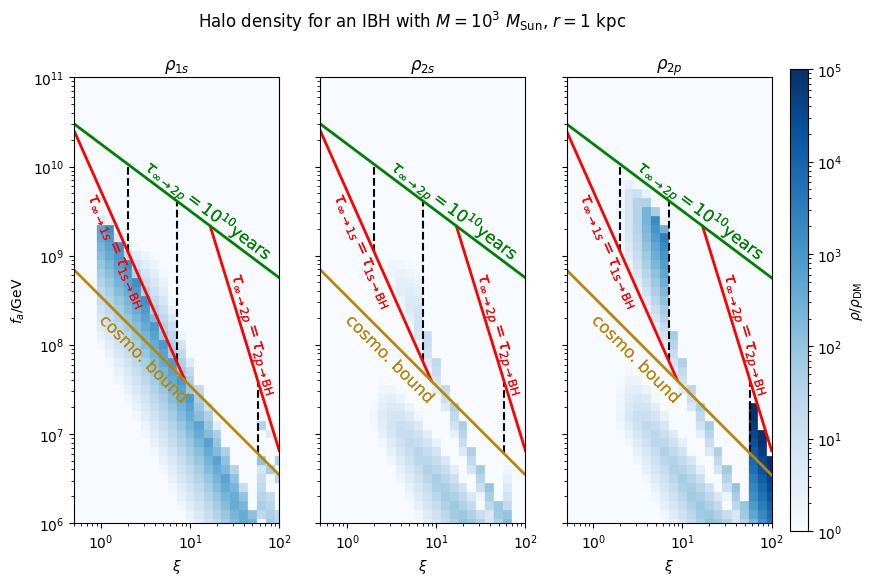

In [ ]:
print(f"N1s min={np.min(N_1s_density_values):.3e}, max={np.max(N_1s_density_values):.3e}")
print(f"N2s min={np.min(N_2s_density_values):.3e}, max={np.max(N_2s_density_values):.3e}")
print(f"N2p min={np.min(N_2p_density_values):.3e}, max={np.max(N_2p_density_values):.3e}")

fig, axes = plt.subplots(1, 3, figsize=(9, 6), sharey=True)
#fig.subplots_adjust(wspace=0)

y_min = 1e4
y_max = 1e9
if (filename.startswith("star")):
  lower_bound = 1e0
  upper_bound = 1e10
elif (filename.startswith("BH")):
  lower_bound = 1e0
  upper_bound = 1e5
elif (filename.startswith("IBH")):
  lower_bound = 1e0
  upper_bound = 1e5
  y_min = 1e6
  y_max = 1e11
elif (filename.startswith("SBH")):
  lower_bound = 1e0
  upper_bound = 1e5
  y_min = 1e8
  y_max = 1e13
elif (filename.startswith("Sun")):
  lower_bound = 1e-2
  upper_bound = 1e0
else:
  print("Unknown astro_regime")

axes[0].set_ylabel(r'$f_a/\text{GeV}$')
for ax in axes:

  ax.set_xscale('log')
  ax.set_yscale('log')
  ax.set_ylim(y_min, y_max)
  ax.set_xlabel(r'$\xi$')
  if filename.startswith("Sun"):
    ax.set_xlim(0.5, 1.82)
    ax.set_aspect(0.2)
    ax.xaxis.set_major_locator(ticker.FixedLocator([0.5,1,1.5]))
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    #ax.set_xticks([0.5,1,1.5],labels=["0.5","1","1.5"])

    secax = ax.secondary_xaxis('top', functions=(lambda x: 0.0154*(x**(-2)), lambda x: 0.124*(x**(-0.5))))
    secax.set_xlabel(r"$r_b/\text{AU}$")

    #secax.xaxis.set_major_locator(ticker.FixedLocator([0.015, 0.01]))
    #ax.xaxis.set_minor_locator(ticker.NullLocator())
    secax.set_xticks([0.01,0.05,0.005,0.0001],labels=["0.01","0.05","0.005","0.0001"])
  else:
    ax.set_xlim(0.5, 100)
    ax.set_aspect(1)


ax = axes[0]
mesh = plot_on_grid(ax, xi_values, f_values, N_1s_density_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{1s}$, kg')
ax.set_title(r"$\rho_{1s}$")

ax = axes[1]
mesh = plot_on_grid(ax, xi_values, f_values, N_2s_density_values, lower_bound, upper_bound)
#fig.colorbar(mesh, ax=ax, label='$M_{2s}$, kg')
ax.set_title(r"$\rho_{2s}$")

ax = axes[2]
mesh = plot_on_grid(ax, xi_values, f_values, N_2p_density_values, lower_bound, upper_bound)
ax.set_title(r"$\rho_{2p}$")

cax = fig.add_axes((0.92, 0.11, 0.02, 0.77))
fig.colorbar(mesh, cax=cax, label=r'$\rho/\rho_{\text{DM}}$')



if ((filename.startswith("BH"))or(filename.startswith("IBH"))or(filename.startswith("SBH"))):
  XIS=np.logspace(np.log10(0.5),2,500)

  halo_1s = 0.1424 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-9/4) #tau_halo(1s) = $tau_{1s->BH} line
  halo_2p = 0.4425 * (rho_tilde)**0.5 * M_tilde * (XIS*0.0008)**(-13/4) # tau_halo(2p) = $tau_{2p->BH} line
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)
  halo_lifetime = (1e10)**0.25 * 378.5 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(2p) = 10^10 years
  halo_1s_masked = np.where( (halo_1s <= halo_lifetime) & (halo_1s >= cosmo_bound), halo_1s, np.nan)
  halo_2p_masked = np.where( (halo_2p <= halo_lifetime) & (halo_2p >= cosmo_bound), halo_2p, np.nan)
  # halo_1s_masked = np.where( (halo_1s <= halo_lifetime), halo_1s, np.nan)
  # halo_2p_masked = np.where( (halo_2p <= halo_lifetime), halo_2p, np.nan)
  indx_strong = (np.abs(XIS - 57)).argmin()
  indx_weak = (np.abs(XIS - 7)).argmin()
  indx2 = (np.abs(XIS - 2)).argmin()


  for i in range(3):
    ax=axes[i]
    ax.plot([XIS[indx_weak],XIS[indx_weak]],[halo_1s[indx_weak], halo_lifetime[indx_weak]],'k--',linewidth=1.5)
    ax.plot([XIS[indx_strong],XIS[indx_strong]],[cosmo_bound[indx_strong], halo_2p[indx_strong]],'k--',linewidth=1.5)
    ax.plot([XIS[indx2],XIS[indx2]],[halo_1s[indx2], halo_lifetime[indx2]],'k--',linewidth=1.5)
    ax.plot(XIS,halo_1s_masked, 'r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 1s}=\\tau_{\\text{1s}\\rightarrow \\text{BH}}$")
    ax.plot(XIS,halo_2p_masked, 'r',linewidth=2, label="$\\tau_{\\infty \\rightarrow 2p}=\\tau_{2p \\rightarrow \\text{BH}}$")
    ax.plot(XIS,halo_lifetime, 'g',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")


    # ax.plot([XIS[indx_strong],XIS[indx_strong]],[halo_1s[indx_strong], halo_2p[indx_strong]],'w--',linewidth=2)


    ax.plot(XIS,cosmo_bound,'darkgoldenrod',linewidth=2,label='cosmo. bound')
    labeled_lines = [line for line in ax.get_lines()]
    labelLines(labeled_lines, align=True, xvals=np.array([2,40,10,5]),xoffsets=[-0.5,10,6,-2], fontsize=12,outline_width=0)

elif (filename.startswith("Sun"))or(filename.startswith("star")):
  XIS=np.logspace(np.log10(0.5),2,500)
  halo_lifetime = (1e10)**0.25 * 381 * (rho_tilde)**0.5 * M_tilde**0.75 * (XIS*0.0008)**(-0.75) #tau_halo(1s) = 10^10 years
  cosmo_bound = 277 * M_tilde * (XIS*0.0008)**(-1)

  for i in range(3):
    ax=axes[i]
    ax.plot(XIS,halo_lifetime, 'g',linewidth=2, label="$\\tau_{\\infty\\rightarrow 2p}=10^{10} \\text{years}$")
    ax.plot(XIS,cosmo_bound,'c',linewidth=2,label='cosmological bound')
    labeled_lines = [line for line in ax.get_lines()]

    labelLines(labeled_lines, align=True, xvals=np.array([1,1]),xoffsets=[-0.5,10,3,-2], fontsize=12,outline_width=0)


if (filename.startswith("star")):
  plt.savefig("star_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for a star with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("BH")):
  plt.savefig("BH_density_parameter_space.png", bbox_inches="tight")
  plt.suptitle(r"Halo density for a BH with $M=10\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("IBH")):
  plt.savefig("IBH_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for an IBH with $M=10^3\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("SBH")):
  plt.savefig("SBH_density_parameter_space.pdf", bbox_inches="tight")
  plt.suptitle(r"Halo density for an SBH with $M=10^5\ M_{\text{Sun}}$, $r=1\ \text{kpc}$")
elif (filename.startswith("Sun")):
  plt.savefig("Sun_density_parameter_space.pdf", bbox_inches="tight")
  #plt.suptitle(r"Halo density for the Sun $M=M_{\text{Sun}}$, $r=8\ \text{kpc}$")
else:
  print("Unknown astro_regime")



plt.show()

# parameter space

/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child9), but could not find a label for it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/labellines/core.py:181: UserWarning: Tried to label line Line2D(_child10), but could not find a label for it.
  warnings.warn(


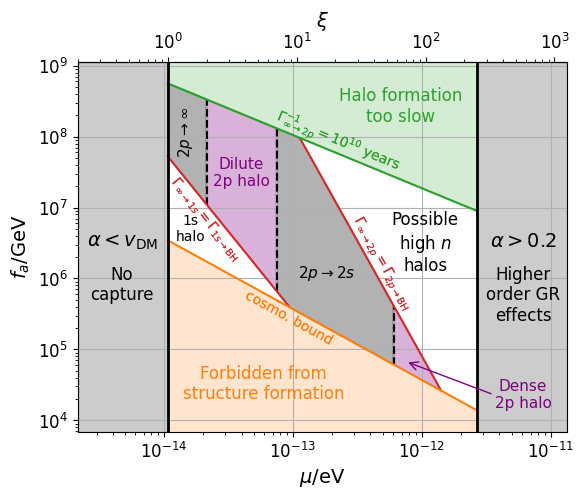

In [ ]:
def NFW(r,rho_s=0.38,rs=18600):
    '''NFW density profile in units of GeV/cm^3. r,rs measured in pc, rho_s measured in GeV/cm^3'''

    return rho_s/(r/rs * (1+r/rs)**2)



def plot_parameter_space(R=1000,v=0.0008,M=10, first_axis="alpha", second_axis="", coherence=False,N=500,save=False,  title="", labelregions=True):
  '''R = distance from the galactic center where rho is evaluated (using an NFW profile).
  v = background velocity (measured in c).
  M = mass of the black hole (measured in solar masses).
  first_axis = the x axis variable. can be "mu","xi" or "alpha".
  second_axis = the second x axis variable. can be left blank, or as another of the first_axis variables.
  coherence = True or False, whether or not to plot the coherence line.
  N = the number of points in the plot.
  save = True or False, whether to save the plot.
  title = add a plot title manually. if left blank an automatic title with R and M is shown. If set to "-1" no title is added.'''

  Rho = NFW(R)/0.4 #rho tilde
  V=v/0.0008
  xlabels = {"mu":"$\\mu$/eV","xi":"$\\xi$","alpha":"$\\alpha$"}

  if first_axis=="alpha":
    ratio = 1

  elif first_axis=="xi":
    ratio = 1/0.0008
  elif first_axis=="mu":
    ratio = 1.3369e-10 / M

  if second_axis=="alpha":
    ratio2 = 1
  elif second_axis=="xi":
    ratio2 = 1/0.0008
  elif second_axis=="mu":
    ratio2 = 1.3369e-10 / M

  plt.figure()
  ax = plt.gca()
  if second_axis!="":
    #fig, ax = plt.subplots(layout='constrained')
    secax = ax.secondary_xaxis('top', functions=(lambda x: ratio2*x/ratio, lambda x: ratio*x/ratio2))
    secax.set_xlabel(xlabels[second_axis],size=14)
    secax.tick_params(labelsize=12)

  ALPHA = 10**np.linspace(np.log10(v),np.log10(0.2),N)

  indx={}
  indx["xi_strong"] = (np.abs(ALPHA - 57*v)).argmin()
  indx["xi_weak"] = (np.abs(ALPHA - 7*v)).argmin()
  indx["xi2"] = (np.abs(ALPHA - 2*v)).argmin()

  halo_1s = 0.1424 * (Rho/V)**0.5 * M * ALPHA**(-9/4) #tau_halo(1s) = $tau_{1s->BH} line
  halo_2p = 0.4425 * (Rho/V)**0.5 * M * ALPHA**(-13/4) # tau_halo(2p) = $tau_{2p->BH} line
  cosmo_bound = 277 * M * ALPHA**(-1)
  halo_coherence = 9.996 * (Rho)**0.5 * V**(-1) * M * ALPHA**(-1) # tau_halo(2p) = tau_{coherence} line
  halo_lifetime = (1e10)**0.25 * 378.5 * (Rho/V)**0.5 * M**0.75 * ALPHA**(-0.75) #tau_halo(2p) = 10^10 years
  halo_1s_masked = np.where( (halo_1s <= halo_lifetime) & (halo_1s >= cosmo_bound), halo_1s, np.nan)
  halo_2p_masked = np.where( (halo_2p <= halo_lifetime) & (halo_2p >= cosmo_bound), halo_2p, np.nan)

  lowerline = np.where( (halo_1s >= cosmo_bound), halo_1s, cosmo_bound)
  upperline = np.where( (halo_2p <= halo_lifetime), halo_2p, halo_lifetime)

  indx["1s-cosmo"] = (np.abs(halo_1s - cosmo_bound)).argmin()
  indx["2p-lifetime"] = (np.abs(halo_2p - halo_lifetime)).argmin()
  indx["2p-cosmo"] = (np.abs(halo_2p - cosmo_bound)).argmin()

  ALPHA *= ratio


  # Shortened white lines for the 2p exponential rate regimes
  #plt.plot([xi_strong,xi_strong],[cosmo_bound[idx_strong], halo_2p[idx_strong]],'k--')
  plt.vlines(ALPHA[indx["xi_weak"]],max(halo_1s[indx["xi_weak"]],cosmo_bound[indx["xi_weak"]]), min(halo_2p[indx["xi_weak"]],halo_lifetime[indx["xi_weak"]]),color='k',linestyle="dashed",linewidth=1.5)
  plt.vlines(ALPHA[indx["xi_strong"]], cosmo_bound[indx["xi_strong"]], halo_2p[indx["xi_strong"]], color="k", linestyle="dashed",linewidth=1.5)
  plt.vlines(ALPHA[indx["xi2"]], halo_1s_masked[indx["xi2"]], halo_lifetime[indx["xi2"]], color="k", linestyle="dashed",linewidth=1.5)


  # Plots
  plt.plot(ALPHA,halo_1s_masked, 'C3', label=r"$\Gamma_{\infty \rightarrow 1s}=\Gamma_{1s\rightarrow \text{BH}}$")
  plt.plot(ALPHA,halo_2p_masked, 'C3', label=r"$\Gamma_{\infty \rightarrow 2p}=\Gamma_{2p\rightarrow \text{BH}}$")
  plt.plot(ALPHA,halo_lifetime, 'C2', label=r"$\Gamma^{-1}_{\infty\rightarrow 2p}=10^{10}$ years")
  plt.plot(ALPHA,cosmo_bound,color='C1',label='cosmo. bound')
  if coherence:
    plt.plot(ALPHA, halo_coherence,'m', label="$\\tau_{\\text{coherence}}=\\tau_{\\infty\\rightarrow 2p}$")

    # left-right Bounds and vertical indicators
  plt.axvspan(ALPHA[0]/5,ALPHA[0],color='k',alpha=0.2)
  plt.axvspan(ALPHA[-1],ALPHA[-1]*5,color='k',alpha=0.2)
  plt.axvline(ALPHA[0], color="k", linewidth=2)
  plt.axvline(ALPHA[-1], color='k', linewidth=2)
  plt.annotate(r'$\alpha<v_{\text{DM}}$', xy=(0.093, 0.5), xycoords='axes fraction',size=14,ha="center")
  plt.annotate('$\\alpha>0.2$', xy=(0.91, 0.5), xycoords='axes fraction',size=14,ha="center")



  #upper and lower bounds
  plt.fill_between([ALPHA[0],ALPHA[-1]],[halo_lifetime[0],halo_lifetime[-1]],[10*halo_lifetime[0],10*halo_lifetime[0]],color='C2',alpha=0.2)
  plt.fill_between([ALPHA[0],ALPHA[-1]],[cosmo_bound[0],cosmo_bound[-1]],color='C1',alpha=0.2)

  plt.xticks(fontsize=12)
  plt.yticks(fontsize=12)



  plt.xlabel(xlabels[first_axis], size=14)
  plt.ylabel('$f_a/\\text{GeV}$', size=14)
  if title=="-1":
    pass
  elif title!="":
    plt.title(title,size=24)
  else:
    plt.title("$M={0}M_\\odot, r={1} $ pc".format(M,int(R)),size=24)
  plt.xscale('log')
  plt.yscale('log')
  plt.xlim((ALPHA[0]/5,5*ALPHA[-1]))

  plt.ylim((cosmo_bound[-1]/2,halo_lifetime[0]*2))
  plt.grid()

  # drawing black and purple regions
  plt.fill_between(ALPHA,upperline,lowerline, where= (lowerline<upperline)*((ALPHA[indx["xi_weak"]]>ALPHA)*(ALPHA[indx["xi2"]]<ALPHA)+(ALPHA>ALPHA[indx["xi_strong"]])),color="purple",alpha=0.3)
  plt.fill_between(ALPHA,upperline,lowerline, where= (lowerline<upperline)*((ALPHA[indx["xi_weak"]]<ALPHA)*((ALPHA<ALPHA[indx["xi_strong"]])) + (ALPHA[indx["xi2"]]>ALPHA)),color='k',alpha=0.3)

  #labeling regions
  if labelregions:
    plt.annotate('No\ncapture', xy=(0.09, 0.45), xycoords='axes fraction',size=12,ha="center",va="top",color="black")
    plt.annotate('Higher\norder GR\neffects', xy=(0.91, 0.45), xycoords='axes fraction',size=12,ha="center",va="top",color="black")
    plt.annotate('Forbidden from\nstructure formation', xy=(0.38, 0.13), xycoords='axes fraction',size=12,ha="center",va="center",color="C1")
    plt.annotate('Halo formation\ntoo slow', xy=(0.66, 0.88), xycoords='axes fraction',size=12,ha="center",va="center",color="C2")
    plt.annotate('Dilute\n2p halo', xy=(0.334, 0.7), xycoords='axes fraction',size=11,ha="center",va="center",color="purple")
    plt.annotate('Dense\n2p halo', xy=(0.91, 0.1), xycoords='axes fraction',size=11,ha="center",va="center",color="purple")
    plt.annotate('1s\nhalo', xy=(0.23, 0.55), xycoords='axes fraction',size=10,ha="center",va="center",color="black")
    plt.annotate('Possible\nhigh'+r' $n$'+'\nhalos', xy=(0.71, 0.51), xycoords='axes fraction',size=12,ha="center",va="center",color="black")
    plt.annotate(r'$2p\rightarrow\infty$', xy=(0.22, 0.81), xycoords='axes fraction',size=11,ha="center",va="center",color="black",rotation=90)
    plt.annotate(r'$2p\rightarrow 2s$', xy=(0.51, 0.43), xycoords='axes fraction',size=11,ha="center",va="center",color="black")
    ax.annotate("", xytext=(0.85, 0.1), xy=(0.67, 0.19),xycoords='axes fraction', arrowprops=dict(arrowstyle="->", color="purple"),size=15)

  # Filtering for lines with labels to avoid warnings

  labeled_lines = [line for line in plt.gca().get_lines()]
  #cosmo_line = [line for line in labeled_lines if line.get_label()=="cosmological bound"]
  #i#f coherence:
   # coh_line=[line for line in labeled_lines if line.get_label()=="$\\tau_{\\text{coherence}}=\\tau_{\\infty\\rightarrow 2p}$"]
   # labeled_lines.remove(coh_line[0])
   # labelLines(coh_line, align=True, xvals=[ratio*0.012], fontsize=12,outline_width=3)
  #labeled_lines.remove(cosmo_line[0])
  labelLines(plt.gca().get_lines(), align=True, xvals=ratio*np.array([0.002, 0.03, 0.01, 0.01]), xoffsets= ratio*np.array([-0.0004,0.007,0.007,-0.003]), fontsize=10,outline_width=0)
  #labelLines(cosmo_line, align=True, xvals=[ratio*0.012], yoffsets=[-8e4], fontsize=12,outline_width=3)
  ax.set_aspect(0.55)
  if save:
    plt.savefig("capturing parameter space.pdf", bbox_inches='tight', format="pdf")


plot_parameter_space(M=10,R=1000,first_axis="mu",second_axis="xi",title="-1",save=True)